# Impute your own dataset
## Goal
Upload a table with **samples in rows and numeric variables in columns**. Use the repository's existing nine-method workflow to optimize hyperparameters, compare reconstruction under MCAR/MAR/MNAR, select the method with the lowest validation RMSE, and impute your original dataset. Download the completed CSV with the original row order, column order, IDs, and metadata.

**Workflow preserved:** this notebook calls the existing `pipeline.tune()`, `pipeline.evaluate()`, original method adapters/search spaces, and `paper_seed_rmse_boxplots.py` without modifying them. The clinical-association stage is omitted. No CVD label or phenotype table is required.

**Reference requirement:** the existing reconstruction benchmark needs genuinely complete measurements. Use complete rows across all selected variables, or upload a separate complete reference table with the same variables and units. At least 50 complete reference rows are required by this companion. If none are available, the notebook explains the requirement and stops; it does not pre-impute unknown values and treat them as truth.

The final selected method is refitted on **all rows of your original dataset**, including its native missing values. Benchmark reference selection never removes rows or variables from the final export. Input values are used on their supplied scale, with the original methods' internal preprocessing unchanged.

## Setup
### 1. Clone the source repository
This is the same clone setup used by the TCGA notebook. Existing checkouts are reused. For a newer source version, start a fresh Colab runtime. Uploaded files and result folders are never automatically committed to GitHub.

In [1]:
from pathlib import Path
import os, sys, shutil, subprocess

REPOSITORY_URL = 'https://github.com/niloofarmaani/proteomics-imputation-benchmark-cvd-association.git'
REPOSITORY_REF = 'main'
CLONE_DIR = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / 'imputation-reproducibility'

# Reuse an existing checkout. In Colab, prefer the dedicated clone directory.
ROOT = next((p.resolve() for p in [CLONE_DIR, Path.cwd(), *Path.cwd().parents]
             if (p/'.git').exists() and (p/'reproducibility/pipeline.py').is_file()), None)
# Local readers can also run directly from an already extracted project folder.
if ROOT is None and not Path('/content').is_dir():
    ROOT = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                 if (p/'reproducibility/pipeline.py').is_file()), None)

if ROOT is None:
    if shutil.which('git') is None:
        raise RuntimeError('Git is not installed. Install Git before running this cell.')
    if CLONE_DIR.exists():
        raise RuntimeError(f'{CLONE_DIR} already exists but is not a valid project checkout. Choose a different CLONE_DIR.')
    print('Cloning the source repository...')
    subprocess.run(['git', 'clone', '--depth', '1', '--branch', REPOSITORY_REF,
                    REPOSITORY_URL, str(CLONE_DIR)],
                   env={**os.environ, 'GIT_TERMINAL_PROMPT': '0'}, check=True)
    ROOT = CLONE_DIR.resolve()

if not (ROOT/'reproducibility/pipeline.py').is_file():
    raise RuntimeError('The checkout does not contain the benchmark source modules.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Repository:', ROOT)
if (ROOT/'.git').exists():
    SOURCE_COMMIT = subprocess.check_output(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'], text=True).strip()
    print('Source commit:', SOURCE_COMMIT)

Repository: /workspace/scratch/39657a1bda5d/figure2-update
Source commit: 7f035fea342fa3a77d6d6935217890a086862056


### 2. Install the same Python and R dependencies
Uses the existing installer and original implementations: KNN, Iterative, MissForest, SoftImpute, AE, DAE, VAE, GAIN, and Transformer. Restart once if the installer reports that already-loaded packages changed, then rerun from the beginning.

In [2]:
import subprocess
import importlib.metadata
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and os.environ.get('IMPUTATION_SKIP_INSTALL') != '1':
    loaded_before = {name: getattr(sys.modules.get(name), '__version__', None) for name in ['numpy', 'pandas', 'scipy', 'sklearn']}
    subprocess.run(['bash', str(ROOT/'scripts/install_colab.sh')], check=True)
    package_names = {'sklearn': 'scikit-learn'}
    changed = [name for name, version in loaded_before.items() if version is not None and version != importlib.metadata.version(package_names.get(name, name))]
    if changed:
        raise RuntimeError('Installed versions changed for already loaded packages: ' + ', '.join(changed) + '. Restart the runtime, then Run all again. Uploaded source files remain available.')
else:
    print('Local run: install requirements.txt and run Rscript scripts/install_r.R before continuing.')

Local run: install requirements.txt and run Rscript scripts/install_r.R before continuing.


### 3. Choose the existing experiment budget
`demo` keeps the existing quick budget: two trials per method, 30 neural epochs, and final seed 42. `paper_budget` keeps the existing method-specific trial counts, 300 epochs, and five final seeds. For five-seed plots with the quick tuning budget, explicitly replace `settings.final_seeds` below.

The tuning panel remains **MAR/MNAR × 10%/30%, seed 42**, with the original additional validation holdouts. Final reconstruction remains **MCAR/MAR/MNAR × 10%/30%/50%**. No new tuning objective, scaling procedure, search space, or imputation method is introduced. Full runs on large matrices can take substantial time.

In [3]:
import json
import numpy as np
import pandas as pd
from IPython.display import display
from reproducibility.pipeline import Settings, tune, evaluate
from reproducibility.methods import METHODS, PAPER_TRIALS, preflight
from reproducibility.user_data import (
    load_uploaded_data, reference_for_benchmark, initialize_uploaded_run,
    select_by_validation, impute_selected_dataset, plot_uploaded_benchmark,
    write_worked_example,
)

MODE = 'demo'  # 'demo' or 'paper_budget'
if MODE not in {'demo', 'paper_budget'}:
    raise ValueError('Choose demo or paper_budget.')
settings = Settings() if MODE == 'demo' else Settings.paper_budget()
# Optional quick-budget five-seed plots, with every other setting unchanged:
# from dataclasses import replace
# settings = replace(settings, final_seeds=(42, 100, 2024, 777, 999))

OUT = ROOT/'results'/pd.Timestamp.now(tz='UTC').strftime('own_data_%Y%m%dT%H%M%S%fZ')
print(preflight(list(settings.methods)))
print('Final seeds:', settings.final_seeds)
display(pd.DataFrame({'method': METHODS, 'trials': [PAPER_TRIALS[m] if MODE == 'paper_budget' else settings.trials for m in METHODS]}))

{'torch': '2.14.1+cpu', 'device': 'cpu', 'methods': ['KNN', 'Iterative', 'MissForest', 'SoftImpute', 'AE', 'DAE', 'VAE', 'GAIN', 'Transformer']}
Final seeds: (42,)


,method,trials
0,KNN,2
1,Iterative,2
2,MissForest,2
3,SoftImpute,2
4,AE,2
5,DAE,2
6,VAE,2
7,GAIN,2
8,Transformer,2


## Steps
### 4. Upload your dataset
CSV and TSV are supported. Use one header row. Empty cells, `NA`, `N/A`, `NaN`, `null`, and `None` are treated as missing **in numeric variables**. Numeric values are not rescaled or encoded by this notebook. Put measurements on a scientifically meaningful common scale before upload because RMSE depends on the supplied units.

- `ID_COLUMN='auto'` recognizes a single `eid`, `sample_id`, `patient_id`, `id`, or `Unnamed: 0` column. Set a column name explicitly when needed, or `None` when there is no ID column.
- Put labels, outcomes, batch information, and other non-imputed columns in `METADATA_COLUMNS`, for example `['label']`. They are kept in the exported CSV and never passed to the imputers.
- All other columns must be numeric variables. Their full names and ordering are preserved. A fully missing variable cannot be estimated by these original adapters and is reported as an input error.

Keep `INPUT_MODE='upload'` to use your data in Colab. `example` generates an explicitly synthetic test dataset; `path` reads an existing local file. The example is for checking execution, not a scientific result.

In [4]:
INPUT_MODE = os.environ.get('IMPUTATION_INPUT_MODE', 'upload')  # 'upload', 'path', 'example'
INPUT_PATH = ''  # For INPUT_MODE='path', enter the absolute CSV/TSV path.
ID_COLUMN = 'auto'
METADATA_COLUMNS = []  # Example: ['label', 'batch']; these columns are never imputed.
CSV_SEPARATOR = None   # None = comma for CSV, tab for TSV; or set ',' / '\t'.

UPLOAD_DIR = ROOT/'data/user_uploads'
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
if INPUT_MODE == 'example':
    input_path = write_worked_example(UPLOAD_DIR/'synthetic_own_data_example.csv')
    print('Using synthetic execution example.')
elif INPUT_MODE == 'path':
    input_path = Path(INPUT_PATH).expanduser().resolve()
elif INPUT_MODE == 'upload':
    if not IN_COLAB:
        raise RuntimeError("For local use, set INPUT_MODE='path' and INPUT_PATH, or choose 'example'.")
    from google.colab import files
    os.chdir(UPLOAD_DIR)
    try:
        uploaded = files.upload()
    finally:
        os.chdir(ROOT)
    if len(uploaded) != 1:
        raise ValueError('Upload exactly one input CSV/TSV.')
    input_path = UPLOAD_DIR/Path(next(iter(uploaded))).name
else:
    raise ValueError('Choose upload, path, or example.')

data = load_uploaded_data(input_path, id_column=ID_COLUMN,
                          metadata_columns=METADATA_COLUMNS, separator=CSV_SEPARATOR)
print('Input samples:', len(data.matrix), '| numeric variables:', len(data.feature_columns))
print('ID column:', data.id_column, '| preserved metadata:', data.metadata_columns)
print('Native missing measurements:', int(data.matrix.isna().sum().sum()))
display(pd.DataFrame({'variable': data.feature_columns,
                      'missing_cells': data.matrix.isna().sum().to_numpy(),
                      'missing_fraction': data.matrix.isna().mean().to_numpy()}).head(30))

Using synthetic execution example.
Input samples: 256 | numeric variables: 60
ID column: sample_id | preserved metadata: []
Native missing measurements: 1054


,variable,missing_cells,missing_fraction
0,measurement 01,22,0.085938
1,measurement 02,20,0.078125
2,measurement 03,17,0.066406
3,measurement 04,13,0.050781
4,measurement 05,18,0.070312
5,measurement 06,16,0.062500
6,measurement 07,19,0.074219
7,measurement 08,15,0.058594
8,measurement 09,13,0.050781
9,measurement 10,17,0.066406


### 5. Provide complete reference values for the unchanged benchmark
Default `complete_rows` uses every fully observed row across the same selected variables. This does not search for a smaller variable panel and does not pre-impute the reference. At least 50 such rows are required.

If your input lacks enough complete rows, use `upload_reference` or `reference_path`. The separate table must have the **same variable names, measurement units, and preprocessing**. Its variable order can differ because names are matched explicitly. Set its own ID/metadata settings below. The reference must be complete. No hidden/native missing measurement is ever treated as known truth.

The reference determines which dataset the method ranking applies to. Complete-case selection can be unrepresentative of the incomplete rows. A separate reference may differ from your target data. The resulting winner is therefore the best validation performer on this reference and budget, not a guarantee about unknown values.

In [5]:
REFERENCE_MODE = 'complete_rows'  # 'complete_rows', 'upload_reference', or 'reference_path'
REFERENCE_PATH = ''
REFERENCE_ID_COLUMN = 'auto'
REFERENCE_METADATA_COLUMNS = []
REFERENCE_SEPARATOR = None
reference_data = None

if REFERENCE_MODE == 'upload_reference':
    if not IN_COLAB:
        raise RuntimeError("Use REFERENCE_MODE='reference_path' locally.")
    from google.colab import files
    reference_dir = UPLOAD_DIR/'reference'
    reference_dir.mkdir(exist_ok=True)
    os.chdir(reference_dir)
    try:
        uploaded_reference = files.upload()
    finally:
        os.chdir(ROOT)
    if len(uploaded_reference) != 1:
        raise ValueError('Upload exactly one complete reference CSV/TSV.')
    reference_path = reference_dir/Path(next(iter(uploaded_reference))).name
elif REFERENCE_MODE == 'reference_path':
    reference_path = Path(REFERENCE_PATH).expanduser().resolve()
elif REFERENCE_MODE != 'complete_rows':
    raise ValueError('Choose a documented reference mode.')

if REFERENCE_MODE != 'complete_rows':
    reference_data = load_uploaded_data(reference_path, id_column=REFERENCE_ID_COLUMN,
                                      metadata_columns=REFERENCE_METADATA_COLUMNS,
                                      separator=REFERENCE_SEPARATOR)
reference, input_audit = reference_for_benchmark(data, reference_data)
display(pd.Series(input_audit, name='Input/reference audit'))
OUT = initialize_uploaded_run(data, reference, settings, OUT, input_audit, reference_data)
print('Run directory:', OUT)

Run directory: /workspace/scratch/39657a1bda5d/figure2-update/results/own_data_20261016T104031379418Z


reference_source           complete rows of the uploaded dataset, across ...
reference_samples                                                        160
input_samples                                                            256
variables                                                                 60
native_missing_cells                                                    1054
native_missing_fraction                                              0.06862
Name: Input/reference audit, dtype: object

### 6. Inspect the original simulation and validation masks
Calls the existing missingness and validation-mask functions. All methods get identical masks. Validation holdouts are disjoint from simulated test omissions. Rank-block MAR/MNAR retain the documented meaning and limitations of the original public workflow; they do not identify your input's real missingness mechanism.

In [6]:
from reproducibility.missingness import corrupt, validation_mask, combo_seed
preview, simulated_mask = corrupt(reference, 'MAR', .3, settings.tuning_seed)
heldout_mask = validation_mask(preview, combo_seed(settings.tuning_seed, 'MAR', .3))
assert not (simulated_mask & heldout_mask).any()
display(pd.DataFrame({'cells': [int(simulated_mask.sum()), int(heldout_mask.sum())]},
                     index=['Original simulated test omissions', 'Additional tuning holdouts']))

,cells
Original simulated test omissions,2880
Additional tuning holdouts,600


### 7. Optimize hyperparameters and freeze one configuration per method
This is the existing `tune()` call. Its objective remains mean validation RMSE across the original four tuning conditions. The same implementations, search spaces, internal early stopping/refit, and failure behavior are retained. A failed method stops the workflow instead of silently selecting from a smaller set.

The lowest frozen validation RMSE selects the method to refit later. That choice is recorded **before** final reconstruction is evaluated. Ties follow the configured method order.

In [7]:
frozen = tune(reference, OUT, settings)
selected_method, validation_ranking = select_by_validation(frozen, settings.methods)
validation_ranking.to_csv(OUT/'method_selection.csv', index=False)
(OUT/'selected_method_before_final_evaluation.json').write_text(json.dumps({
    'method': selected_method,
    'selection': 'lowest frozen validation RMSE before final reconstruction evaluation',
}, indent=2))
trials = pd.read_csv(OUT/'validation_trials.csv')
display(trials[['method', 'trial', 'state', 'objective']].round(5))
display(validation_ranking.round(5))
print('Validation-selected method:', selected_method)
display(pd.DataFrame([{'method': method, 'frozen_parameters': json.dumps(item['params'])}
                      for method, item in frozen.items()]))

Tuning KNN
Tuning Iterative
Tuning MissForest
Tuning SoftImpute
Tuning AE
Tuning DAE
Tuning VAE
Tuning GAIN
Tuning Transformer
Validation-selected method: Iterative


,method,trial,state,objective
0,KNN,0,COMPLETE,0.43865
1,KNN,1,COMPLETE,0.46707
2,Iterative,0,COMPLETE,0.22611
3,Iterative,1,COMPLETE,0.22611
4,MissForest,0,COMPLETE,0.32581
5,MissForest,1,COMPLETE,0.32058
6,SoftImpute,0,COMPLETE,0.33990
7,SoftImpute,1,COMPLETE,0.24145
8,AE,0,COMPLETE,0.52499
9,AE,1,COMPLETE,0.73448


,validation_rank,method,validation_rmse,best_trial,trials
0,1,Iterative,0.22611,0,2
1,2,SoftImpute,0.24145,1,2
2,3,MissForest,0.32058,1,2
3,4,GAIN,0.34141,0,2
4,5,KNN,0.43865,0,2
5,6,DAE,0.49801,0,2
6,7,AE,0.52499,0,2
7,8,Transformer,0.64217,0,2
8,9,VAE,0.77070,0,2


,method,frozen_parameters
0,KNN,"{""k"": 5}"
1,Iterative,"{""max_iter"": 25, ""tol"": 0.001, ""n_nearest_feat..."
2,MissForest,"{""niter"": 3, ""ntree"": 200, ""max_depth"": 20, ""s..."
3,SoftImpute,"{""rank_max"": 5, ""maxit"": 50}"
4,AE,"{""batch_size"": 64, ""learning_rate"": 0.00076611..."
5,DAE,"{""batch_size"": 64, ""learning_rate"": 0.00076611..."
6,VAE,"{""batch_size"": 64, ""learning_rate"": 0.00076611..."
7,GAIN,"{""batch_size"": 64, ""lr"": 0.0007661100707771367..."
8,Transformer,"{""batch_size"": 32, ""nhead"": 4, ""num_layers"": 1..."


### 8. Compare reconstruction with the existing frozen-parameter evaluation
This is the unchanged `evaluate()` call. It scores RMSE only at simulated missing measurements in the complete reference. The original 10%/30%/50% MCAR/MAR/MNAR comparison is retained. Final benchmark scores are reported for comparison and do not replace the validation-selected winner.

The supplied method named SoftImpute retains the original rank-truncated SVD implementation, including its documented difference from singular-value-shrinkage SoftImpute.

In [8]:
reconstruction = evaluate(reference, OUT, settings, frozen)
comparison = reconstruction.groupby(['method', 'mechanism', 'fraction']).rmse.mean().unstack(['mechanism', 'fraction'])
display(comparison.round(5))
print('Final scores describe the complete reference, not errors at unknown native missing cells.')

Final KNN: MCAR_0.1_seed42
Final Iterative: MCAR_0.1_seed42
Final MissForest: MCAR_0.1_seed42
Final SoftImpute: MCAR_0.1_seed42
Final AE: MCAR_0.1_seed42
Final DAE: MCAR_0.1_seed42
Final VAE: MCAR_0.1_seed42
Final GAIN: MCAR_0.1_seed42
Final Transformer: MCAR_0.1_seed42
Final KNN: MCAR_0.3_seed42
Final Iterative: MCAR_0.3_seed42
Final MissForest: MCAR_0.3_seed42
Final SoftImpute: MCAR_0.3_seed42
Final AE: MCAR_0.3_seed42
Final DAE: MCAR_0.3_seed42
Final VAE: MCAR_0.3_seed42
Final GAIN: MCAR_0.3_seed42
Final Transformer: MCAR_0.3_seed42
Final KNN: MCAR_0.5_seed42
Final Iterative: MCAR_0.5_seed42
Final MissForest: MCAR_0.5_seed42
Final SoftImpute: MCAR_0.5_seed42
Final AE: MCAR_0.5_seed42
Final DAE: MCAR_0.5_seed42
Final VAE: MCAR_0.5_seed42
Final GAIN: MCAR_0.5_seed42
Final Transformer: MCAR_0.5_seed42
Final KNN: MAR_0.1_seed42
Final Iterative: MAR_0.1_seed42
Final MissForest: MAR_0.1_seed42
Final SoftImpute: MAR_0.1_seed42
Final AE: MAR_0.1_seed42
Final DAE: MAR_0.1_seed42
Final VAE: M

mechanism        MAR                    ...     MNAR                  
fraction         0.1      0.3      0.5  ...      0.1      0.3      0.5
method                                  ...                           
AE           0.45950  0.55565  0.58589  ...  0.44946  0.52836  0.64929
DAE          0.42921  0.50929  0.54673  ...  0.41949  0.48679  0.64095
GAIN         0.25860  0.34937  0.39137  ...  0.25579  0.30969  0.37425
Iterative    0.17979  0.26618  0.25863  ...  0.18797  0.26832  0.26896
KNN          0.37635  0.58753  0.82496  ...  0.43477  0.72760  0.98082
MissForest   0.26487  0.33596  0.38870  ...  0.29981  0.39950  0.59994
SoftImpute   0.29247  0.25113  0.23798  ...  0.30006  0.27977  0.23204
Transformer  0.53413  0.64125  0.77030  ...  0.49908  0.58178  0.73226
VAE          0.67209  0.75906  0.85559  ...  0.72790  0.82788  0.94936

[9 rows x 9 columns]

### 9. Generate the original paper-style comparison plot
Uses `legacy/Evaluation/paper_seed_rmse_boxplots.py`, with the same colours, method order, grouped missingness fractions, and stacked mechanism panels. Dataset labels and RMSE units refer to your uploaded reference.

With one seed, collapsed boxes show individual scores and provide no replicate uncertainty estimate. Five seeds produce IQR boxes, median lines, 1.5-IQR whiskers, and individual seed points. PDF, 300-dpi PNG, per-seed values, and summaries are saved.

PDF: /workspace/scratch/39657a1bda5d/figure2-update/results/own_data_20261016T104031379418Z/figures/Figure1_RMSE_All_Conditions.pdf
PNG: /workspace/scratch/39657a1bda5d/figure2-update/results/own_data_20261016T104031379418Z/figures/Figure1_RMSE_All_Conditions.png


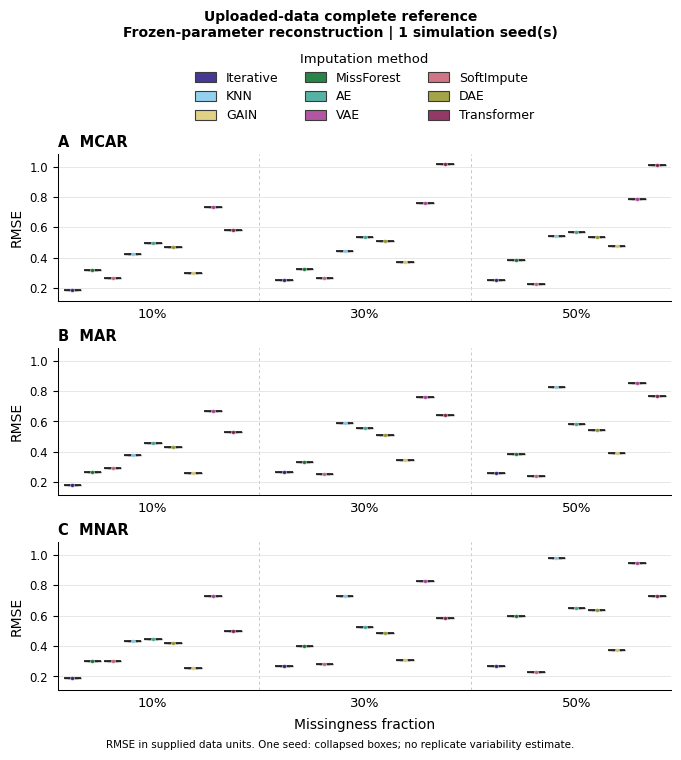

,missingness,fraction,method,count,mean,std
0,MAR,0.1,AE,1,0.45950,NaN
1,MAR,0.1,DAE,1,0.42921,NaN
2,MAR,0.1,GAIN,1,0.25860,NaN
3,MAR,0.1,Iterative,1,0.17979,NaN
4,MAR,0.1,KNN,1,0.37635,NaN
...,...,...,...,...,...,...
76,MNAR,0.5,KNN,1,0.98082,NaN
77,MNAR,0.5,MissForest,1,0.59994,NaN
78,MNAR,0.5,SoftImpute,1,0.23204,NaN
79,MNAR,0.5,Transformer,1,0.73226,NaN


In [9]:
plot_outputs, plotted_values, reconstruction_summary = plot_uploaded_benchmark(reconstruction, OUT, settings)
print('PDF:', plot_outputs['main_all_conditions_figure']['pdf'])
print('PNG:', plot_outputs['main_all_conditions_figure']['png'])
display(reconstruction_summary[['missingness', 'fraction', 'method', 'count', 'mean', 'std']].round(5))

### 10. Refit the selected method on your original dataset
The original method adapter now receives **all original rows and selected numeric variables**, with their actual native missing values and the frozen hyperparameters. IDs and metadata stay outside the imputer. No unknown reference values or clinical labels are supplied to fitting.

The export restores original column names and order, keeps sample IDs (including leading zeros), preserves observed measurement strings and metadata, and fills only originally missing numeric measurements. The completed dataset is not one of the artificially corrupted benchmark matrices. If your input was already complete, the export is unchanged and no unnecessary final fit is claimed.

In [10]:
best_csv, best_imputed = impute_selected_dataset(data, OUT, settings, frozen, selected_method)
print('Selected original method:', selected_method)
print('Original samples retained:', len(best_imputed))
print('Originally missing measurements filled:', input_audit['native_missing_cells'])
print('Completed dataset:', best_csv)
display(best_imputed.head())
display(pd.Series(json.loads((OUT/'best_method.json').read_text()), name='Selected method and export'))
# Show actual filled cells, including samples outside the complete reference.
changed_cells = []
for i, j in np.argwhere(data.matrix.isna().to_numpy())[:12]:
    column = data.feature_columns[j]
    changed_cells.append({'sample': data.original.iloc[i][data.id_column] if data.id_column else int(i) + 1,
                          'variable': column, 'before': data.original.iloc[i][column],
                          'imputed': best_imputed.iloc[i][column]})
if changed_cells:
    display(pd.DataFrame(changed_cells))


Selected original method: Iterative
Original samples retained: 256
Originally missing measurements filled: 1054
Completed dataset: /workspace/scratch/39657a1bda5d/figure2-update/results/own_data_20261016T104031379418Z/best_imputed_dataset.csv


,sample_id,measurement 01,measurement 02,measurement 03,measurement 04,measurement 05,measurement 06,measurement 07,measurement 08,measurement 09,measurement 10,measurement 11,measurement 12,measurement 13,measurement 14,measurement 15,measurement 16,measurement 17,measurement 18,measurement 19,measurement 20,measurement 21,measurement 22,measurement 23,measurement 24,measurement 25,measurement 26,measurement 27,measurement 28,measurement 29,measurement 30,measurement 31,measurement 32,measurement 33,measurement 34,measurement 35,measurement 36,measurement 37,measurement 38,measurement 39,measurement 40,measurement 41,measurement 42,measurement 43,measurement 44,measurement 45,measurement 46,measurement 47,measurement 48,measurement 49,measurement 50,measurement 51,measurement 52,measurement 53,measurement 54,measurement 55,measurement 56,measurement 57,measurement 58,measurement 59,measurement 60
0,00000,-1.7426265112942005,-1.6488648738895213,-1.4294199431875358,0.3208985909974234,0.8478934258500147,-1.5882987843067458,1.7147977166826909,-2.039738912605999,-1.0593762871822228,-0.45493693554227077,0.12214916544059203,0.2073793595853364,1.3872112011394957,0.20599539270635117,0.7209585668876737,-0.42735252950270963,1.1201494885464647,-0.17673817736095868,1.046320941706904,-2.354304827437462,0.769929459343155,1.6665853898933278,1.8112330013219835,0.6182046960838288,-0.7855313021476116,0.9915805108436945,0.4511882409998684,-0.9535432269860454,-0.36423120210356824,1.2823118957394815,0.6287021130161401,-0.6809958874718911,-1.0047131808045986,1.681592587573378,-1.4698641977085807,-1.7787474100062515,-0.10928395329655761,0.7767006232939124,-0.05796329226847388,0.7757489909509839,-0.8711702708975456,-0.31753437901977744,-0.6883854142627772,1.3528088559961913,0.22722507744579884,-1.6896075931050036,1.387801025871386,-0.30468314035202576,-1.010248295963477,-2.1183791206402707,-1.5066373544065002,1.8147854413798206,0.17530375973423715,0.7119356521867863,0.05037167589514809,-1.6413614694704988,0.8856270232085548,0.22265055728521432,-0.9060475984571723,1.3906294898634748
1,00001,-0.560899515775585,-0.05323269144796454,-1.062012952841894,0.5876993604114216,0.6337653704837335,-0.11476514917238295,0.5597175533292279,-1.3165834789512663,-1.036357848764723,-0.21548010033673937,-0.005423658420843801,-0.3803697126571003,0.6113349155588507,-0.5018056000352019,0.0031314221518540845,0.549784390390589,1.3345807063671664,0.6019232695189305,0.7165175635771761,-1.2213234243658362,-0.5576323148013125,0.8238648331896814,0.6601049911886991,0.09490007365273587,-0.04469442139763343,0.6322645061550908,-0.6138352441121714,-0.5525237743559803,-0.9086473695513476,0.1707695328652277,-0.6522064025406387,-1.3461525055594754,-0.6928321018082458,1.0267140778643902,0.1323035043756633,-0.874310423865353,-0.900893033642222,-0.3488837642088551,-0.6448965506195589,0.9978624150238731,-1.1272515371476872,-0.3467876577876221,0.15974181615053895,1.4295602228673514,-0.5654891024854726,-1.0617590983738558,0.8687026130629397,0.6255547064166602,-1.1292709603570386,-0.7909082966684742,-0.7341890258275277,1.4864271205951405,-0.15497202568647472,-0.3122357572744003,-0.8935789998696202,-1.4858100958192593,0.2731547401828663,-0.017369870756988856,-0.4445884611106411,0.4919432969326938
2,00002,0.8879090094132828,1.4679684586027812,1.1991166619289622,0.45663761942076964,0.8602682604212403,1.8915503879087383,-1.0716695411490877,0.2097127563878347,-0.7815306831249591,-0.2291718415122965,0.3568537338851233,-0.5876617418469275,-0.4143581475127967,-0.7231683258089782,0.8455541999559335,1.192832164718489,-0.2391926328019663,-0.003665038571069999,-0.13978894399377062,1.2611965175344382,-1.5424143094074816,-0.9790293414987683,-0.2583519598065613,-0.5283058105647402,1.158475951752483,-1.796491382395001,-0.4233396221798419,1.574225000892557,-1.4439779343378043,-2.9048750016046796,-0.1417459471876485,-0.940875703760192,-0.2687848409266113,-0.7111851625712082,2.065744836884785,1.068200298752491,-1.

method                                                                 Iterative
selection                      lowest validation RMSE; never selected using f...
validation_rmse                                                         0.226109
parameters                     {'max_iter': 25, 'tol': 0.001, 'n_nearest_feat...
refit_seed                                                                    42
native_missing_cells_filled                                                 1054
original_samples                                                             256
variables                      [measurement 01, measurement 02, measurement 0...
refitted_on_original_data                                                   True
output_sha256                  9354ec246fbf6fa27533dae933be255532d5222fb9b8b9...
Name: Selected method and export, dtype: object

,sample,variable,before,imputed
0,00160,measurement 02,,1.4305034789570741
1,00160,measurement 06,,1.365153021477842
2,00160,measurement 12,,-1.1474962360901098
3,00160,measurement 20,,0.43586293812866989
4,00160,measurement 24,,-0.82010874718561633
5,00160,measurement 25,,0.3866640253472558
6,00160,measurement 30,,-1.1378072254910991
7,00160,measurement 33,,-0.37286502222788909
8,00160,measurement 40,,0.56558590189188829
9,00160,measurement 43,,1.0587573021352092


## Checks
### 11. Verify the comparison and export
Checks cover the full method/mechanism/fraction/seed grid, finite scores, selection based only on the frozen validation results, complete numeric output, and preservation of observed values, IDs, and metadata. The original reference benchmark and final original-data imputation have separate output files.

In [11]:
expected = len(settings.methods)*len(settings.mechanisms)*len(settings.fractions)*len(settings.final_seeds)
assert len(reconstruction) == expected
assert not reconstruction.duplicated(['method', 'mechanism', 'fraction', 'seed']).any()
assert np.isfinite(reconstruction.rmse).all()
assert select_by_validation(frozen, settings.methods)[0] == selected_method
assert best_imputed.columns.equals(data.original.columns)
assert len(best_imputed) == len(data.original)
for j, column in enumerate(data.feature_columns):
    originally_observed = data.matrix.iloc[:, j].notna().to_numpy()
    assert best_imputed.loc[originally_observed, column].equals(data.original.loc[originally_observed, column])
    assert np.isfinite(pd.to_numeric(best_imputed[column]).to_numpy()).all()
for column in [c for c in data.original if c not in data.feature_columns]:
    assert best_imputed[column].equals(data.original[column])
print(f'Complete reconstruction grid: {len(reconstruction)}/{expected}')
print('All original rows, variable ordering, observed measurements, IDs and metadata preserved.')
print('Every originally missing numeric measurement is filled.')

Complete reconstruction grid: 81/81
All original rows, variable ordering, observed measurements, IDs and metadata preserved.
Every originally missing numeric measurement is filled.


## Next Steps
### 12. Download the best method's imputed CSV
This file contains your original table with only missing numeric measurements filled. Excluded metadata columns can still contain their original missing entries. The download runs in Colab; local users can open the printed output path.

In [12]:
if IN_COLAB:
    from google.colab import files
    files.download(str(best_csv))
else:
    print('Best imputed CSV:', best_csv)

Best imputed CSV: /workspace/scratch/39657a1bda5d/figure2-update/results/own_data_20261016T104031379418Z/best_imputed_dataset.csv


### 13. Keep the complete results bundle
The archive includes your input table, reference matrix, masks, Optuna study, tuning tables, frozen parameters, reconstruction comparisons, figures, selected-method record, logs, environment, and completed CSV. It is created in your runtime and is not uploaded to GitHub. Set `DOWNLOAD_FULL_BUNDLE=True` to download it as well.

In [13]:
DOWNLOAD_FULL_BUNDLE = False
archive = shutil.make_archive(str(OUT), 'zip', root_dir=OUT)
print('Results bundle:', archive)
if IN_COLAB and DOWNLOAD_FULL_BUNDLE:
    from google.colab import files
    files.download(archive)

Results bundle: /workspace/scratch/39657a1bda5d/figure2-update/results/own_data_20261016T104031379418Z.zip
